# Figure 4

In [ ]:
from riskhistory.format import rcParams
from riskhistory.config import results_pth
from riskhistory.utils import bootstrap_spearman_difference
from riskhistory.data import (
    load_loo_comparison,
    load_ddm_subj_params,
    load_choicehistorypersubject,
    load_rtlme_switchpersubject_betas,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pingouin as pg
import statsmodels.api as sm

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
STP_DDM_MODEL = "HDDM_Base_Lag1-full"
DRIFT_DDM_MODEL = "HDDM_Base_Lag1-full"
VAL_DDM_MODEL = "HDDM_Base_Lag1-full"

### Helper functions

In [32]:
BF_THRESHOLD_HIGH = 3
BF_THRESHOLD_LOW = 1 / 3

BF_COLORS = {
    "evidence_for":     "#017D01",
    "inconclusive":     "#B0B0B0",
    "evidence_against": "#000000",
}


def bf_category(bf10):
    if bf10 > BF_THRESHOLD_HIGH:
        return "evidence_for"
    if bf10 < BF_THRESHOLD_LOW:
        return "evidence_against"
    return "inconclusive"


def spearman_corr_bf(x, y):
    """Spearman rho, p and BF10 (Pearson on ranks), plus an OLS line and 95% CI on the raw points."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    res = pg.corr(pd.Series(x).rank().values, pd.Series(y).rank().values).iloc[0]
    bf10 = float(res["BF10"])

    ols_fit = sm.OLS(y, sm.add_constant(x)).fit()
    x_line = np.linspace(x.min(), x.max(), 100)
    pred = ols_fit.get_prediction(sm.add_constant(x_line)).summary_frame(alpha=0.05)

    return {
        "r": float(res["r"]),
        "pval": float(res["p_val"]),
        "bf10": bf10,
        "category": bf_category(bf10),
        "n": len(x),
        "x_line": x_line,
        "y_line": pred["mean"].values,
        "ci_low": pred["mean_ci_lower"].values,
        "ci_high": pred["mean_ci_upper"].values,
    }


def style_axis(ax, col=None, ylabel=None, xlabel=None, xlabel_col=1):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0 and ylabel:
        ax.set_ylabel(ylabel)
    else:
        ax.set_ylabel("  \n ")
    if col == xlabel_col and xlabel:
        ax.set_xlabel(xlabel)
    else:
        ax.set_xlabel(" ")


def format_log_bf(bf10):
    return f"{np.log(bf10):.1f}"


def format_pval(p):
    if p < 0.001:
        return "p < .001"
    if p < 0.01:
        return "p < .01"
    if p < 0.05:
        return "p < .05"
    return "n.s."


def plot_spearman_corr(ax, x, y, ylim=None):
    result = spearman_corr_bf(x, y)
    color = BF_COLORS[result["category"]]

    ax.axhline(0, color="black", linestyle="--", linewidth=1, zorder=0)
    ax.scatter(x, y, color=color, alpha=0.75, edgecolor="black",
               linewidth=0.5, s=75, zorder=3)
    ax.fill_between(result["x_line"], result["ci_low"], result["ci_high"],
                    color=color, alpha=0.15, zorder=1)
    ax.plot(result["x_line"], result["y_line"], color=color, linewidth=1.5,
            linestyle="-", zorder=4)

    ax.text(0.05, 0.95,
            f"ρ = {result['r']:.2f}, {format_pval(result['pval'])}\n"
            f"ln(BF10) = {format_log_bf(result['bf10'])}\nn = {result['n']}",
            transform=ax.transAxes, ha="left", va="top", fontsize=16,
            color="black", fontweight="bold")

    if ylim:
        ax.set_ylim(ylim)

    return result

def pair(param, outcome, exclude):
    return pd.concat([param, outcome], axis=1, join="inner").drop(index=exclude, errors="ignore")


def compute_elpd_vs_baseline(dataset, baseline_model, model_order, column="diff_elpd_loo"):
    """LOO elpd diff vs. baseline_model from compare_models.py's pairwise table.
    column="diff_elpd_reliable" restricts to trials with pareto_k <= 0.7 in both models."""
    loo = load_loo_comparison(dataset, group_name="choicehistory")
    diffs = []
    for model_id, _ in model_order:
        row = loo[(loo["reference_model"] == baseline_model) & (loo["target_model"] == model_id)]
        if len(row) != 1:
            raise ValueError(
                f"Expected one {baseline_model} vs {model_id} row, found {len(row)} "
                f"-- check MODEL_GROUPS in compare_models.py."
            )
        diffs.append(row[column].iloc[0])
    return diffs


ELPD_THRESHOLD = 4

ELPD_COLORS = {
    "improved":  "#017D01",
    "ambiguous": "#8D8D8D",
    "worse":     "#980B0B",
}
ELPD_LABELS = {
    "improved":  "∆elpd > 4",
    "ambiguous": "otherwise",
    "worse":     "∆elpd < -4",
}


def elpd_category(diff):
    if diff > ELPD_THRESHOLD:
        return "improved"
    if diff < -ELPD_THRESHOLD:
        return "worse"
    return "ambiguous"


def plot_elpd_bars(ax, diffs, x_labels, col, show_legend=False):
    x_pos = np.arange(len(diffs))
    colors = [ELPD_COLORS[elpd_category(d)] for d in diffs]
    ax.bar(x_pos, diffs, color=colors, width=0.6, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(-8, 200)
    style_axis(ax, col, ylabel="Improvement over \nbaseline DDM (∆elpd-loo)",
               xlabel="DDM parameter(s) shifted by choice history")

    if show_legend:
        handles = [mpatches.Patch(facecolor=ELPD_COLORS[cat], label=ELPD_LABELS[cat])
                   for cat in ("improved", "worse", "ambiguous")]
        ax.legend(handles=handles, loc="upper left")

### Data

In [33]:
BASELINE_MODEL = "HDDM_Base"

ELPD_MODEL_ORDER = [
    ("HDDM_Base_Lag1-stim",  "Gain/Loss\n Drift"),
    ("HDDM_Base_Lag1-drift", "Fixed\n Drift"),
    ("HDDM_Base_Lag1-stp",   "Starting\n Point"),
]

EXCLUDE_DRIFT = {}
EXCLUDE_STP = {}

choicehistory_betas = load_choicehistorypersubject()
choicehistory_betas = choicehistory_betas[choicehistory_betas["success"]]
switch_betas = load_rtlme_switchpersubject_betas()
switch_betas = switch_betas[switch_betas["converged"]]

elpd_vs_baseline = {}
drift_vs_choice = {}
drift_vs_switch = {}
z_vs_choice = {}
z_vs_switch = {}

for ds in DATASETS:
    elpd_vs_baseline[ds] = compute_elpd_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER)

    stp_params = (load_ddm_subj_params(STP_DDM_MODEL, ds)
                  .pivot(index="sub", columns="param_name", values="param_value"))
    drift_params = (load_ddm_subj_params(DRIFT_DDM_MODEL, ds)
                    .pivot(index="sub", columns="param_name", values="param_value"))

    choice_effect = (choicehistory_betas[choicehistory_betas["dataset"] == ds]
                     .set_index("sub")["choicehistory"].rename("choice_prev1_effect"))
    switch_effect = (switch_betas[switch_betas["dataset"] == ds]
                     .set_index("sub")["switch_effect"])

    drift = 2*drift_params["v_choice_prev1"]
    z = 2*stp_params["z_choice_prev1"]
    drift_vs_choice[ds] = pair(drift, choice_effect, EXCLUDE_DRIFT.get(ds, []))
    drift_vs_switch[ds] = pair(drift, switch_effect, EXCLUDE_DRIFT.get(ds, []))
    z_vs_choice[ds] = pair(z, choice_effect, EXCLUDE_STP.get(ds, []))
    z_vs_switch[ds] = pair(z, switch_effect, EXCLUDE_STP.get(ds, []))

### 3x3 figure:
1. LOO improvement
2. Correlation scatterplot
3. Correlation scatterplot

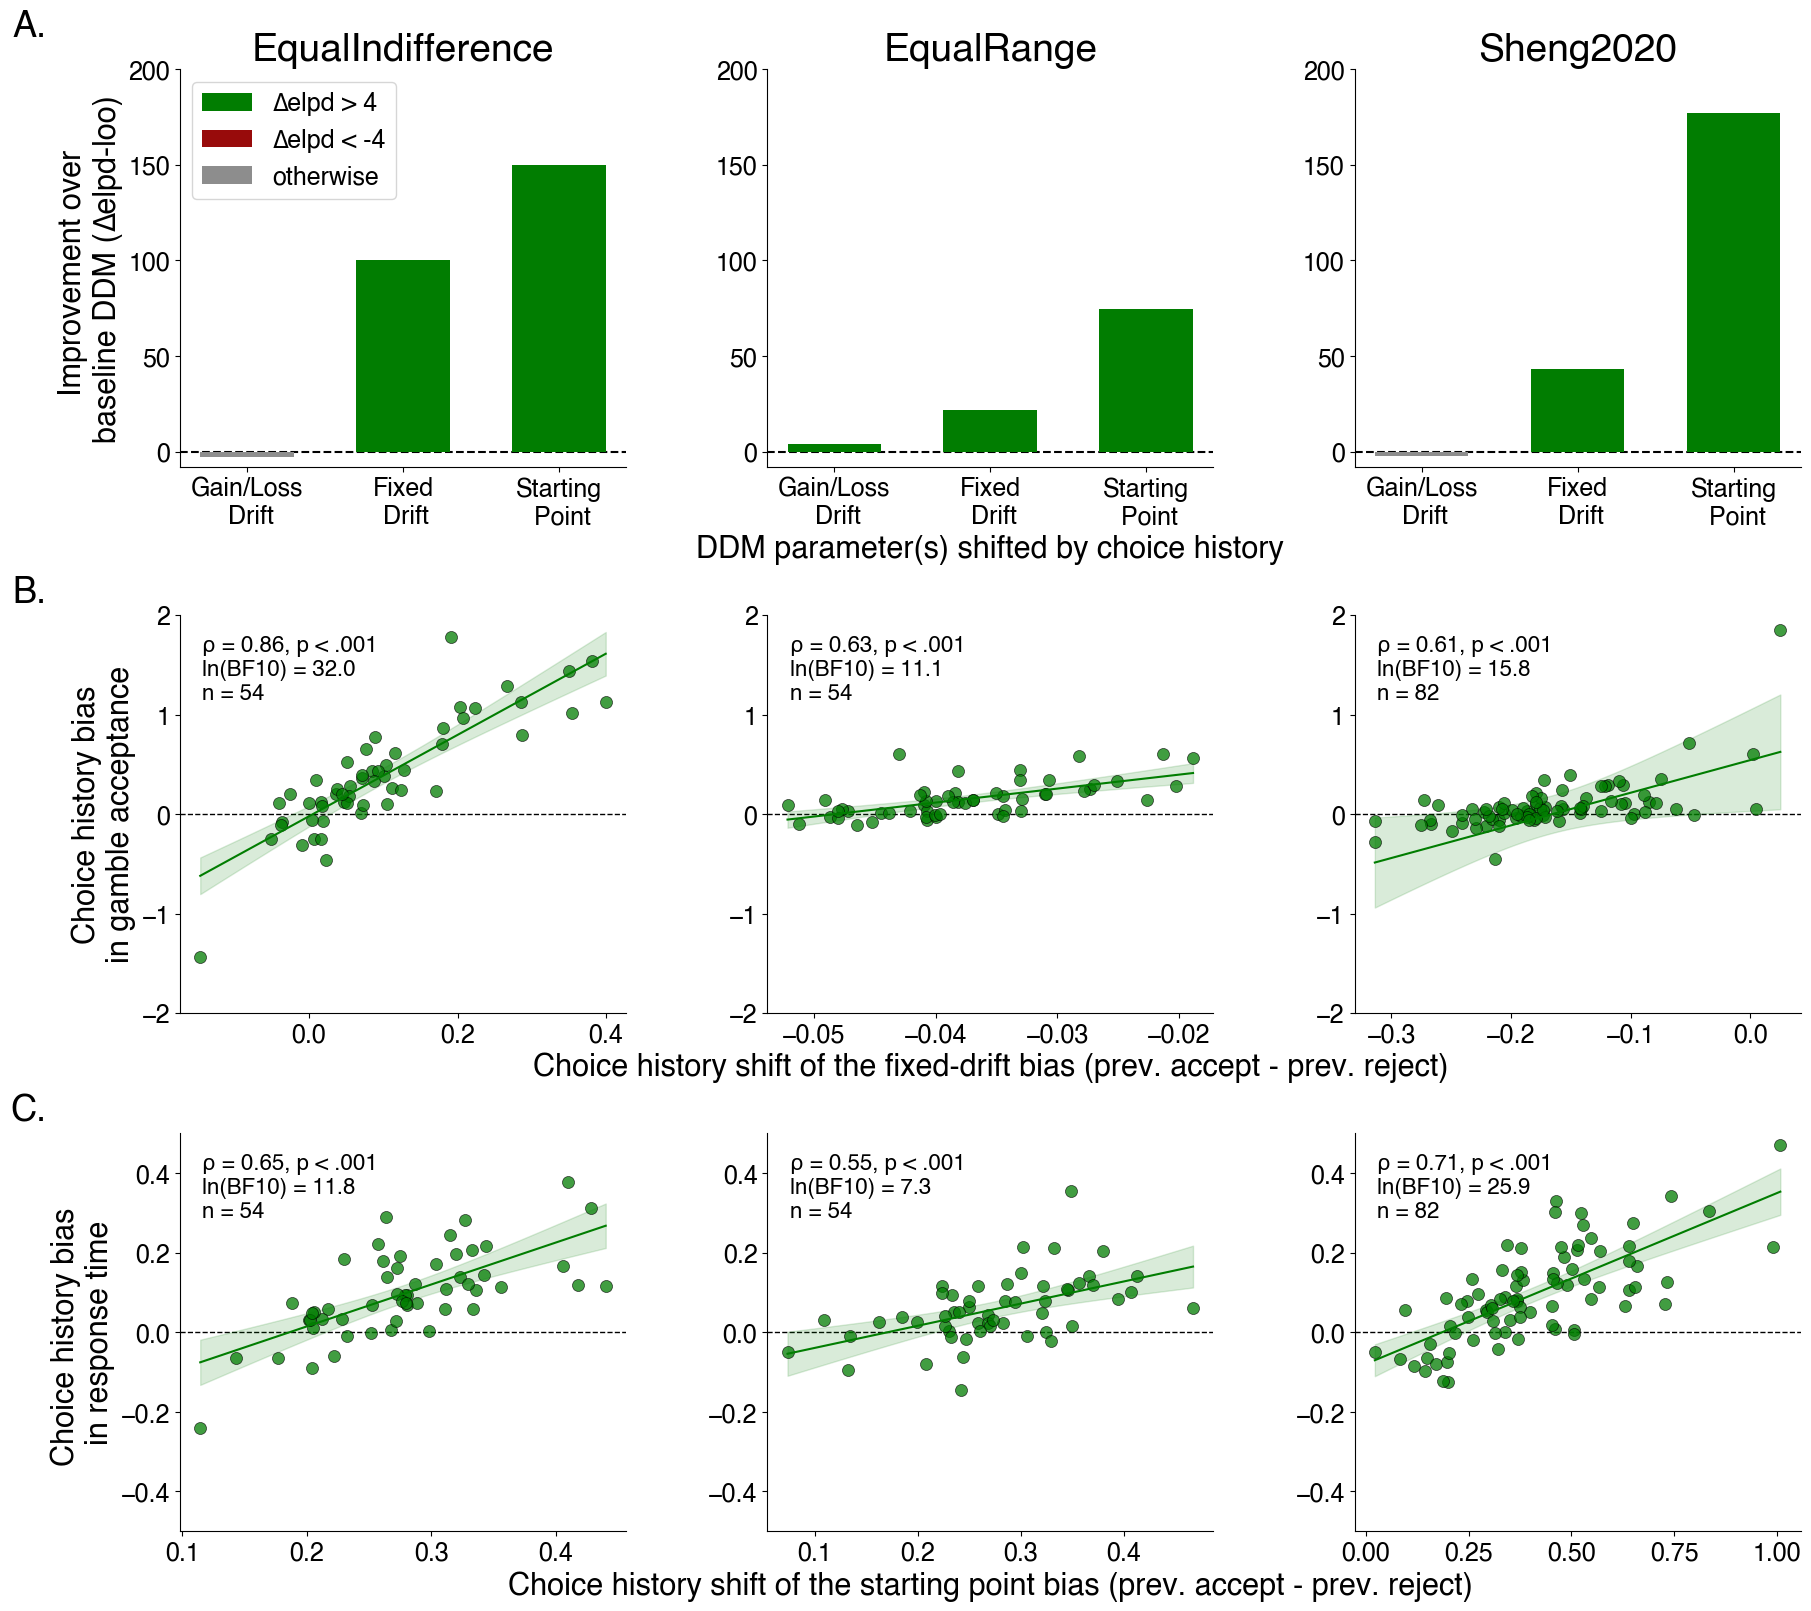

In [35]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 16), layout="constrained")
elpd_labels = [label for _, label in ELPD_MODEL_ORDER]

for col, ds in enumerate(DATASETS):
    plot_elpd_bars(axes[0, col], elpd_vs_baseline[ds], elpd_labels, col, show_legend=(col == 0))
    axes[0, col].set_title(DATASET_LABELS.get(ds, ds))

    merged = drift_vs_choice[ds]
    plot_spearman_corr(axes[1, col], merged["v_choice_prev1"], merged["choice_prev1_effect"], ylim=(-2, 2))
    style_axis(axes[1, col], col,
               ylabel="Choice history bias\nin gamble acceptance",
               xlabel="Choice history shift of the fixed-drift bias (prev. accept - prev. reject)")

    merged = z_vs_switch[ds]
    plot_spearman_corr(axes[2, col], merged["z_choice_prev1"], merged["switch_effect"], ylim=(-0.5, 0.5))
    style_axis(axes[2, col], col,
               ylabel="Choice history bias \nin response time",
               xlabel="Choice history shift of the starting point bias (prev. accept - prev. reject)")

# Same "A."/"B."/"C." placement convention as figure1.ipynb
for row, label in enumerate(["A.", "B.", "C."]):
    y = 1.15 if row == 0 else 1.1
    axes[row, 0].text(-0.3, y, label, transform=axes[row, 0].transAxes,
                      fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure3.svg", dpi=300, bbox_inches="tight")
plt.show()

### Bootstrap: Δρ between DDM choice-history shifts (LaTeX table)
Paired percentile bootstrap (`bootstrap_spearman_difference`, `R = 10000`, no exclusions) of ρ(effect, DDM A shift) − ρ(effect, DDM B shift), written to `results/bootstrap_spearman_tables.tex` in the format of `scripts/5-elpd_tables.py`. Val-CH shift Δλ = λ(prev. accept) − λ(prev. reject), with λ = |v_loss / v_gain|.

In [ ]:
DATASET_NAMES = {
    "equalIndifference": "EqualIndifference",
    "equalRange": "EqualRange",
    "sheng2020": "Sheng2020",
}
DDM_SHIFT_NAMES = {
    "z_choice_prev1":     "SP-CH",
    "v_choice_prev1":     "Drift-CH",
    "loss_aversion_diff": "Val-CH",
}
EFFECT_NAMES = {
    "choice_prev1_effect": "Acceptance",
    "switch_effect":       "RT",
}

# (behavioral effect, DDM A shift, DDM B shift): Δρ = ρ(effect, A) − ρ(effect, B)
BOOTSTRAP_COMPARISONS = [
    ("choice_prev1_effect", "v_choice_prev1", "z_choice_prev1"),
    ("choice_prev1_effect", "v_choice_prev1", "loss_aversion_diff"),
    ("switch_effect",       "z_choice_prev1", "v_choice_prev1"),
    ("switch_effect",       "z_choice_prev1", "loss_aversion_diff"),
]


def loss_aversion_diff(params):
    """λ after accept − λ after reject, with λ = |v_loss / v_gain|."""
    gain, gain_cp = params["v_gain_centered"], params["v_gain_centered:choice_prev1"]
    loss, loss_cp = params["v_loss_centered"], params["v_loss_centered:choice_prev1"]
    lambda_accept = np.abs((loss + loss_cp) / (gain + gain_cp))
    lambda_reject = np.abs((loss - loss_cp) / (gain - gain_cp))
    return (lambda_accept - lambda_reject).rename("loss_aversion_diff")


def load_params(model, ds):
    return load_ddm_subj_params(model, ds).pivot(index="sub", columns="param_name", values="param_value")


def format_delta_rho(res):
    return f"{res['difference']:.2f} [{res['ci_lower']:.2f}, {res['ci_upper']:.2f}]"


def write_bootstrap_table(f, title, caption, table_rows):
    f.write(f"\\subsection*{{{title}}}\n\n")
    f.write("\\begin{table}[h!]\n")
    f.write("\\centering\n")
    f.write("\\begin{tabular}{lll" + "c" * len(DATASETS) + "}\n")
    f.write("\\hline\n")
    header = ["Effect", "DDM A", "DDM B"] + [DATASET_NAMES[ds] for ds in DATASETS]
    f.write(" & ".join(header) + " \\\\\n")
    f.write("\\hline\n")
    for row_cells in table_rows:
        f.write(" & ".join(row_cells) + " \\\\\n")
    f.write("\\hline\n")
    f.write("\\end{tabular}\n")
    f.write(f"\\caption{{{caption}}}\n")
    f.write("\\end{table}\n\n\n")
    f.write("\\newpage\n")


shifts_and_effects = {}
for ds in DATASETS:
    shifts_and_effects[ds] = pd.concat([
        load_params(STP_DDM_MODEL, ds)["z_choice_prev1"],
        load_params(DRIFT_DDM_MODEL, ds)["v_choice_prev1"],
        loss_aversion_diff(load_params(VAL_DDM_MODEL, ds)),
        choicehistory_betas[choicehistory_betas["dataset"] == ds]
            .set_index("sub")["choicehistory"].rename("choice_prev1_effect"),
        switch_betas[switch_betas["dataset"] == ds].set_index("sub")["switch_effect"],
    ], axis=1)

table_rows = []
for effect, shift_a, shift_b in BOOTSTRAP_COMPARISONS:
    row_cells = [EFFECT_NAMES[effect], DDM_SHIFT_NAMES[shift_a], DDM_SHIFT_NAMES[shift_b]]
    for ds in DATASETS:
        df = shifts_and_effects[ds][[effect, shift_a, shift_b]].dropna()
        res = bootstrap_spearman_difference(df[effect], df[shift_a], df[shift_b], random_state=0)
        row_cells.append(format_delta_rho(res))
    table_rows.append(row_cells)

title = "Choice-history DDM shifts vs. behavioral choice-history effects ($\\Delta\\rho$ [95\\% CI])"
caption = (
    "Difference in Spearman correlation between each behavioral choice-history effect "
    "and the DDM A vs. DDM B choice-history shift, "
    "$\\Delta\\rho = \\rho(\\mathrm{effect}, A) - \\rho(\\mathrm{effect}, B)$, "
    "with 95\\% percentile bootstrap CIs (10,000 paired resamples of participants)."
)

output_path = results_pth / "bootstrap_spearman_tables.tex"
with open(output_path, "w") as f:
    write_bootstrap_table(f, title, caption, table_rows)

print(output_path.read_text())